In [2]:
import os
import random
import copy
import time

from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from PIL import Image, ImageFilter

import matplotlib.pyplot as plt

from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

from tqdm.auto import tqdm

d:\Data\AI-edge\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [67]:
PROJECT_ROOT = Path("..").resolve()

DATA_ROOT = PROJECT_ROOT / "data" / "supervisely"

IMAGE_DIR = DATA_ROOT / "images"
MASK_DIR = DATA_ROOT / "masks"

OUTPUT_DIR = PROJECT_ROOT / "outputs"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
FIGURE_DIR = OUTPUT_DIR / "figures"
PRED_DIR = OUTPUT_DIR / "predictions"
RESULT_DIR = OUTPUT_DIR / "results"

for folder in [
    CHECKPOINT_DIR,
    FIGURE_DIR,
    PRED_DIR,
    RESULT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42

IMAGE_SIZE = 256
BATCH_SIZE = 8
EPOCHS = 20
LEARNING_RATE = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Project:", PROJECT_ROOT)
print("Image dir:", IMAGE_DIR)
print("Mask dir:", MASK_DIR)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Project: D:\Data\AI-edge
Image dir: D:\Data\AI-edge\data\supervisely\images
Mask dir: D:\Data\AI-edge\data\supervisely\masks
Device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [7]:
print("IMAGE_DIR exists:", IMAGE_DIR.exists())
print("MASK_DIR exists:", MASK_DIR.exists())

IMAGE_DIR exists: True
MASK_DIR exists: True


In [8]:
image_files = sorted([
    f for f in IMAGE_DIR.iterdir()
    if f.is_file()
])

mask_files = sorted([
    f for f in MASK_DIR.iterdir()
    if f.is_file()
])

print("Images:", len(image_files))
print("Masks :", len(mask_files))

Images: 2667
Masks : 2667


In [9]:
image_map = {
    p.stem: p
    for p in image_files
}

mask_map = {
    p.stem: p
    for p in mask_files
}

sample_ids = sorted(
    set(image_map.keys())
    & set(mask_map.keys())
)

print("Matched:", len(sample_ids))

print(
    "Missing masks:",
    len(set(image_map) - set(mask_map))
)

print(
    "Missing images:",
    len(set(mask_map) - set(image_map))
)

Matched: 2667
Missing masks: 0
Missing images: 0


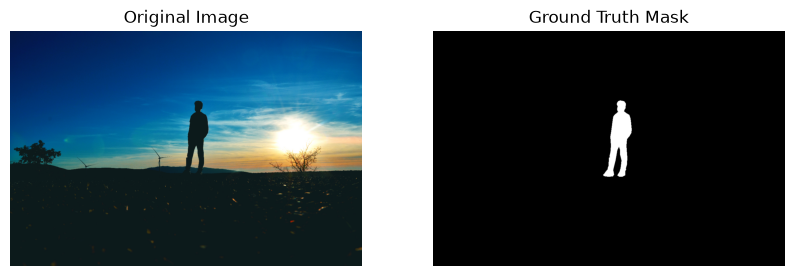

In [10]:
sample_id = sample_ids[0]

image = Image.open(
    image_map[sample_id]
).convert("RGB")

mask = Image.open(
    mask_map[sample_id]
).convert("L")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.show()

In [11]:
mask_np = np.array(mask)

print("Shape:", mask_np.shape)
print("Min:", mask_np.min())
print("Max:", mask_np.max())
print("Unique:", np.unique(mask_np)[:30])

Shape: (800, 1200)
Min: 0
Max: 255
Unique: [  0 255]


In [16]:
generator = torch.Generator()
generator.manual_seed(SEED)

perm = torch.randperm(
    len(sample_ids),
    generator=generator
).tolist()

n = len(sample_ids)

n_train = int(0.8 * n)
n_val = int(0.1 * n)

train_indices = perm[:n_train]
val_indices = perm[n_train:n_train+n_val]
test_indices = perm[n_train+n_val:]

train_ids = [
    sample_ids[i]
    for i in train_indices
]

val_ids = [
    sample_ids[i]
    for i in val_indices
]

test_ids = [
    sample_ids[i]
    for i in test_indices
]

print("Total:", n)
print("Train:", len(train_ids))
print("Val:", len(val_ids))
print("Test:", len(test_ids))

Total: 2667
Train: 2133
Val: 266
Test: 268


In [17]:
class SuperviselyDataset(Dataset):

    def __init__(
        self,
        ids,
        image_map,
        mask_map,
        image_size=256,
        augment=False
    ):
        self.ids = ids
        self.image_map = image_map
        self.mask_map = mask_map
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):

        sample_id = self.ids[index]

        image = Image.open(
            self.image_map[sample_id]
        ).convert("RGB")

        mask = Image.open(
            self.mask_map[sample_id]
        ).convert("L")

        image = TF.resize(
            image,
            [self.image_size, self.image_size],
            interpolation=InterpolationMode.BILINEAR,
            antialias=True
        )

        mask = TF.resize(
            mask,
            [self.image_size, self.image_size],
            interpolation=InterpolationMode.NEAREST
        )

        if self.augment:
            if random.random() < 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)

        # Apply appearance augmentation to training images only; masks stay unchanged.
        if self.augment and random.random() < 0.25:
            image = image.filter(ImageFilter.GaussianBlur(radius=random.uniform(0.3, 1.2)))

        image = TF.to_tensor(image)

        if self.augment and random.random() < 0.35:
            image = (image + torch.randn_like(image) * random.uniform(0.01, 0.05)).clamp_(0.0, 1.0)


        mask = TF.pil_to_tensor(
            mask
        ).float()

        mask = (
            mask > 127
        ).float()

        return image, mask, sample_id

In [18]:
train_dataset = SuperviselyDataset(
    train_ids,
    image_map,
    mask_map,
    image_size=IMAGE_SIZE,
    augment=True
)

val_dataset = SuperviselyDataset(
    val_ids,
    image_map,
    mask_map,
    image_size=IMAGE_SIZE,
    augment=False
)

test_dataset = SuperviselyDataset(
    test_ids,
    image_map,
    mask_map,
    image_size=IMAGE_SIZE,
    augment=False
)

print("Train:", len(train_dataset))
print("Val:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 2133
Val: 266
Test: 268


In [19]:
num_workers=0

In [20]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

In [21]:
images, masks, ids = next(
    iter(train_loader)
)

print("Image batch:", images.shape)
print("Mask batch :", masks.shape)

print(
    "Mask values:",
    torch.unique(masks)
)

Image batch: torch.Size([8, 3, 256, 256])
Mask batch : torch.Size([8, 1, 256, 256])
Mask values: tensor([0., 1.])


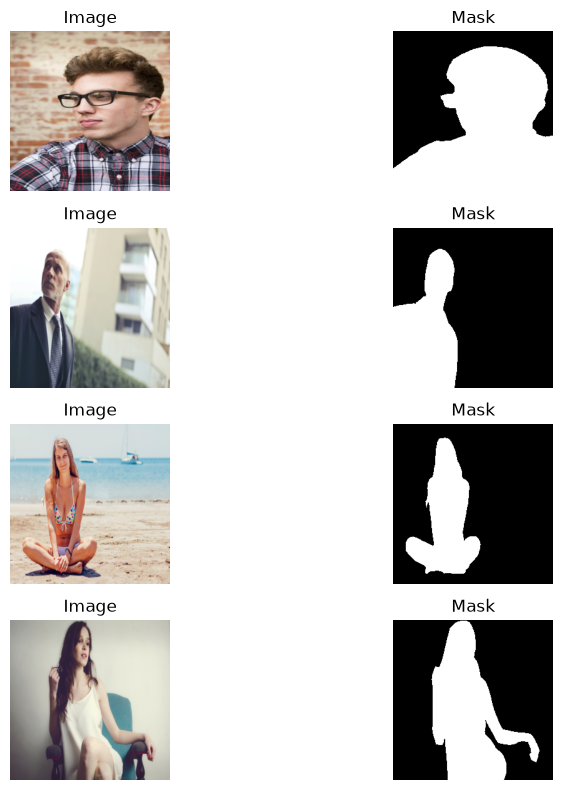

In [22]:
plt.figure(figsize=(10, 8))

for i in range(min(4, len(images))):

    plt.subplot(4, 2, i * 2 + 1)

    plt.imshow(
        images[i].permute(1, 2, 0)
    )

    plt.title("Image")
    plt.axis("off")

    plt.subplot(4, 2, i * 2 + 2)

    plt.imshow(
        masks[i, 0],
        cmap="gray"
    )

    plt.title("Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [23]:
model = torch.hub.load(
    "PeterL1n/RobustVideoMatting",
    "mobilenetv3",
    pretrained=True,
    trust_repo=True
)

model = model.to(device)

print(model)

Downloading: "https://github.com/PeterL1n/RobustVideoMatting/zipball/master" to C:\Users\Tawan-Labtop/.cache\torch\hub\master.zip
Downloading: "https://github.com/PeterL1n/RobustVideoMatting/releases/download/v1.0.0/rvm_mobilenetv3.pth" to C:\Users\Tawan-Labtop/.cache\torch\hub\checkpoints\rvm_mobilenetv3.pth


100%|██████████| 14.5M/14.5M [00:02<00:00, 6.49MB/s]


MattingNetwork(
  (backbone): MobileNetV3LargeEncoder(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
        (2): Hardswish()
      )
      (1): InvertedResidual(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
            (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
            (2): ReLU(inplace=True)
          )
          (1): Conv2dNormActivation(
            (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
            (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
          )
        )
      )
      (2): InvertedResidual(
        (block

In [24]:
model = torch.hub.load(
    "PeterL1n/RobustVideoMatting",
    "mobilenetv3",
    pretrained=True,
    trust_repo=True
)

model = model.to(device)
model.eval()

print("Model loaded successfully")
print("Device:", device)

Model loaded successfully
Device: cuda


Using cache found in C:\Users\Tawan-Labtop/.cache\torch\hub\PeterL1n_RobustVideoMatting_master


In [25]:
print("Backbone:")
print(type(model.backbone))

print("\nASPP:")
print(type(model.aspp))

print("\nDecoder:")
print(type(model.decoder))

print("\nMatting head:")
print(type(model.project_mat))

print("\nSegmentation head:")
print(type(model.project_seg))

print("\nRefiner:")
print(type(model.refiner))

Backbone:
<class 'model.mobilenetv3.MobileNetV3LargeEncoder'>

ASPP:
<class 'model.lraspp.LRASPP'>

Decoder:
<class 'model.decoder.RecurrentDecoder'>

Matting head:
<class 'model.decoder.Projection'>

Segmentation head:
<class 'model.decoder.Projection'>

Refiner:
<class 'model.deep_guided_filter.DeepGuidedFilterRefiner'>


In [26]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 3,748,633
Trainable parameters: 3,748,633


In [27]:
images, masks, ids = next(iter(val_loader))

images = images.to(device)
masks = masks.to(device)

print("Input :", images.shape)
print("Target:", masks.shape)

model.eval()

with torch.no_grad():

    pred_seg, *rec = model(
        images,
        segmentation_pass=True
    )

print("Prediction:", pred_seg.shape)
print("Recurrent states:", len(rec))

Input : torch.Size([8, 3, 256, 256])
Target: torch.Size([8, 1, 256, 256])
Prediction: torch.Size([8, 1, 256, 256])
Recurrent states: 4


In [28]:
pred_prob = torch.sigmoid(pred_seg)

pred_mask = (
    pred_prob >= 0.5
).float()

print("Logit range:")
print(
    pred_seg.min().item(),
    pred_seg.max().item()
)

print("\nProbability range:")
print(
    pred_prob.min().item(),
    pred_prob.max().item()
)

print("\nPrediction mask values:")
print(
    torch.unique(pred_mask)
)

Logit range:
-42.92743682861328 9.194948196411133

Probability range:
2.274317326084123e-19 0.9998984336853027

Prediction mask values:
tensor([0., 1.], device='cuda:0')


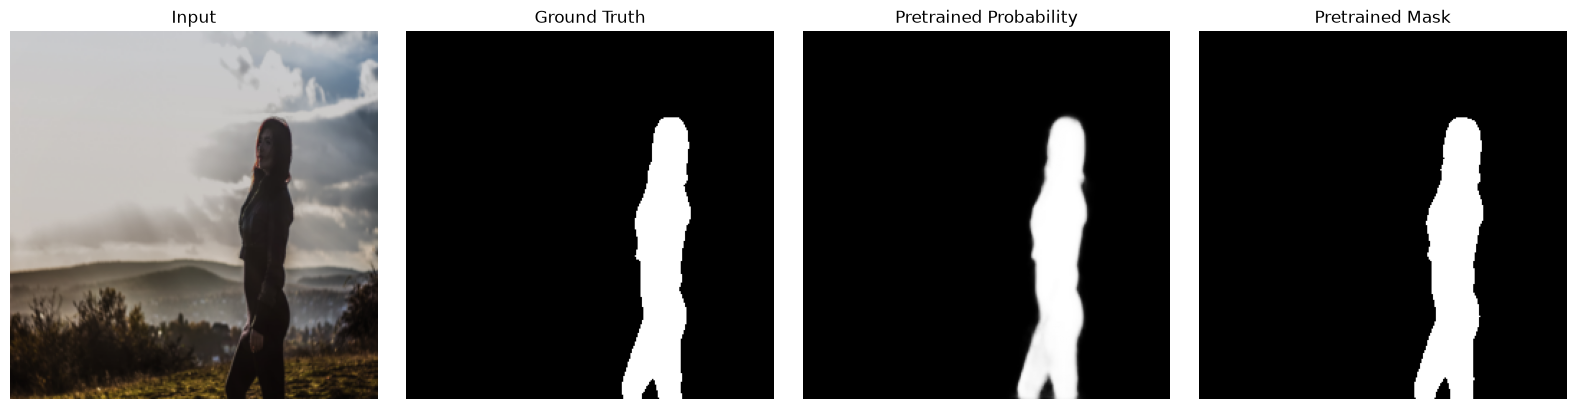

In [29]:
idx = 0

input_img = (
    images[idx]
    .detach()
    .cpu()
    .permute(1, 2, 0)
)

gt_mask = (
    masks[idx, 0]
    .detach()
    .cpu()
)

prob_mask = (
    pred_prob[idx, 0]
    .detach()
    .cpu()
)

binary_pred = (
    pred_mask[idx, 0]
    .detach()
    .cpu()
)

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(input_img)
plt.title("Input")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(gt_mask, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(prob_mask, cmap="gray")
plt.title("Pretrained Probability")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(binary_pred, cmap="gray")
plt.title("Pretrained Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:
criterion = nn.BCEWithLogitsLoss()

In [32]:
loss = criterion(
    pred_seg,
    masks
)

print(
    "Baseline batch BCE Loss:",
    loss.item()
)

Baseline batch BCE Loss: 0.03325584903359413


In [33]:
def calculate_metrics(
    logits,
    targets,
    threshold=0.5,
    eps=1e-8
):

    probs = torch.sigmoid(logits)

    preds = probs >= threshold
    targets = targets >= 0.5

    tp = (preds & targets).sum().item()
    fp = (preds & ~targets).sum().item()
    fn = (~preds & targets).sum().item()
    tn = (~preds & ~targets).sum().item()

    iou = (
        tp /
        (tp + fp + fn + eps)
    )

    dice = (
        2 * tp /
        (2 * tp + fp + fn + eps)
    )

    precision = (
        tp /
        (tp + fp + eps)
    )

    recall = (
        tp /
        (tp + fn + eps)
    )

    return {
        "iou": iou,
        "dice": dice,
        "precision": precision,
        "recall": recall
    }

In [34]:
batch_metrics = calculate_metrics(
    pred_seg,
    masks
)

batch_metrics

{'iou': 0.9497392815758121,
 'dice': 0.9742218260158525,
 'precision': 0.9884676264414536,
 'recall': 0.9603808128889637}

In [35]:
@torch.inference_mode()
def evaluate_model(
    model,
    loader
):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    tp = 0
    fp = 0
    fn = 0
    tn = 0

    for images, masks, _ in tqdm(
        loader,
        desc="Evaluating",
        leave=False
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        logits, *_ = model(
            images,
            segmentation_pass=True
        )

        loss = criterion(
            logits,
            masks
        )

        batch_size = images.size(0)

        total_loss += (
            loss.item()
            * batch_size
        )

        total_samples += batch_size

        probs = torch.sigmoid(logits)

        preds = probs >= 0.5
        targets = masks >= 0.5

        tp += (
            preds & targets
        ).sum().item()

        fp += (
            preds & ~targets
        ).sum().item()

        fn += (
            ~preds & targets
        ).sum().item()

        tn += (
            ~preds & ~targets
        ).sum().item()

    eps = 1e-8

    loss = (
        total_loss
        / total_samples
    )

    iou = (
        tp /
        (tp + fp + fn + eps)
    )

    dice = (
        2 * tp /
        (2 * tp + fp + fn + eps)
    )

    precision = (
        tp /
        (tp + fp + eps)
    )

    recall = (
        tp /
        (tp + fn + eps)
    )

    return {
        "loss": loss,
        "iou": iou,
        "dice": dice,
        "precision": precision,
        "recall": recall
    }

In [36]:
baseline_val = evaluate_model(
    model,
    val_loader
)

baseline_val

{'loss': 0.05250660993887069,
 'iou': 0.9411412105318226,
 'dice': 0.9696782546530701,
 'precision': 0.9808829454663737,
 'recall': 0.9587266565941355}

In [37]:
print("=== PRETRAINED BASELINE : VALIDATION ===")

for key, value in baseline_val.items():
    print(
        f"{key:10s}: {value:.4f}"
    )

=== PRETRAINED BASELINE : VALIDATION ===
loss      : 0.0525
iou       : 0.9411
dice      : 0.9697
precision : 0.9809
recall    : 0.9587


In [38]:
baseline_test = evaluate_model(
    model,
    test_loader
)

print("=== PRETRAINED BASELINE : TEST ===")

for key, value in baseline_test.items():
    print(
        f"{key:10s}: {value:.4f}"
    )

=== PRETRAINED BASELINE : TEST ===
loss      : 0.0659
iou       : 0.9288
dice      : 0.9631
precision : 0.9799
recall    : 0.9468


In [39]:
baseline_df = pd.DataFrame([
    {
        "model": "RVM-MobileNetV3 Pretrained",
        "loss": baseline_test["loss"],
        "iou": baseline_test["iou"],
        "dice": baseline_test["dice"],
        "precision": baseline_test["precision"],
        "recall": baseline_test["recall"]
    }
])

baseline_df

,model,loss,iou,dice,precision,recall
0,RVM-MobileNetV3 Pretrained,0.065852,0.928751,0.963059,0.979876,0.94681


In [41]:
baseline_df.to_csv(
    "../outputs/results/baseline_results.csv",
    index=False
)

In [42]:
baseline_seg_state = copy.deepcopy(
    model.project_seg.state_dict()
)

print("Baseline segmentation head saved.")

Baseline segmentation head saved.


In [43]:
# Freeze ทุก parameter
for param in model.parameters():
    param.requires_grad = False

# เปิด train เฉพาะ segmentation head
for param in model.project_seg.parameters():
    param.requires_grad = True

In [44]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")

print(
    f"Trainable percentage : "
    f"{100 * trainable_params / total_params:.4f}%"
)

Total parameters     : 3,748,633
Trainable parameters : 17
Trainable percentage : 0.0005%


In [45]:
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

project_seg.conv.weight
project_seg.conv.bias


In [46]:
optimizer = torch.optim.Adam(
    model.project_seg.parameters(),
    lr=LEARNING_RATE
)

print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


In [47]:
def train_one_epoch(
    model,
    loader,
    optimizer
):

    # ส่วน pretrained อยู่ใน inference mode
    model.eval()

    # เปิด train mode เฉพาะ segmentation head
    model.project_seg.train()

    running_loss = 0.0
    total_samples = 0

    for images, masks, _ in tqdm(
        loader,
        desc="Training",
        leave=False
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        # ล้าง gradient เก่า
        optimizer.zero_grad()

        # Forward
        logits, *_ = model(
            images,
            segmentation_pass=True
        )

        # Loss
        loss = criterion(
            logits,
            masks
        )

        # Backpropagation
        loss.backward()

        # Update project_seg weights
        optimizer.step()

        batch_size = images.size(0)

        running_loss += (
            loss.item() * batch_size
        )

        total_samples += batch_size

    epoch_loss = (
        running_loss /
        total_samples
    )

    return epoch_loss

In [48]:
model.eval()
model.project_seg.train()

images, masks, _ = next(
    iter(train_loader)
)

images = images.to(device)
masks = masks.to(device)

optimizer.zero_grad()

logits, *_ = model(
    images,
    segmentation_pass=True
)

loss = criterion(
    logits,
    masks
)

loss.backward()

print("Test batch loss:", loss.item())

print(
    "project_seg gradient exists:",
    any(
        p.grad is not None
        for p in model.project_seg.parameters()
    )
)

Test batch loss: 0.20535778999328613
project_seg gradient exists: True


In [68]:
history = {
    "train_loss": [],
    "val_loss": [],
    "val_iou": [],
    "val_dice": [],
    "val_precision": [],
    "val_recall": []
}

best_val_loss = float("inf")

best_checkpoint = (
    CHECKPOINT_DIR /
    "rvm_mobilenetv3_supervisely_best.pth"
)

start_time = time.perf_counter()

for epoch in range(EPOCHS):

    print(
        f"\nEpoch {epoch + 1}/{EPOCHS}"
    )

    # -------------------------
    # Train
    # -------------------------
    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer
    )

    # -------------------------
    # Validation
    # -------------------------
    val_metrics = evaluate_model(
        model,
        val_loader
    )

    # -------------------------
    # History
    # -------------------------
    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_metrics["loss"]
    )

    history["val_iou"].append(
        val_metrics["iou"]
    )

    history["val_dice"].append(
        val_metrics["dice"]
    )

    history["val_precision"].append(
        val_metrics["precision"]
    )

    history["val_recall"].append(
        val_metrics["recall"]
    )

    # -------------------------
    # Print result
    # -------------------------
    print(
        f"Train Loss : {train_loss:.4f}"
    )

    print(
        f"Val Loss   : "
        f"{val_metrics['loss']:.4f}"
    )

    print(
        f"Val IoU    : "
        f"{val_metrics['iou']:.4f}"
    )

    print(
        f"Val Dice   : "
        f"{val_metrics['dice']:.4f}"
    )

    print(
        f"Precision  : "
        f"{val_metrics['precision']:.4f}"
    )

    print(
        f"Recall     : "
        f"{val_metrics['recall']:.4f}"
    )

    # -------------------------
    # Save best checkpoint
    # -------------------------
    if val_metrics["loss"] < best_val_loss:

        best_val_loss = (
            val_metrics["loss"]
        )

        torch.save(
            {
                "epoch":
                    epoch + 1,

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "val_metrics":
                    val_metrics,

                "config": {
                    "image_size":
                        IMAGE_SIZE,

                    "batch_size":
                        BATCH_SIZE,

                    "epochs":
                        EPOCHS,

                    "learning_rate":
                        LEARNING_RATE,

                    "seed":
                        SEED
                }
            },

            best_checkpoint
        )

        print(
            "✓ Best checkpoint saved"
        )


training_seconds = (
    time.perf_counter()
    - start_time
)

print("\nTraining complete")

print(
    f"Total training time: "
    f"{training_seconds:.2f} seconds"
)

print(
    f"Best validation loss: "
    f"{best_val_loss:.4f}"
)


Epoch 1/20


Train Loss : 0.0598
Val Loss   : 0.0478
Val IoU    : 0.9433
Val Dice   : 0.9708
Precision  : 0.9750
Recall     : 0.9666
✓ Best checkpoint saved

Epoch 2/20


Train Loss : 0.0593
Val Loss   : 0.0477
Val IoU    : 0.9434
Val Dice   : 0.9709
Precision  : 0.9748
Recall     : 0.9670
✓ Best checkpoint saved

Epoch 3/20


Train Loss : 0.0600
Val Loss   : 0.0476
Val IoU    : 0.9435
Val Dice   : 0.9709
Precision  : 0.9745
Recall     : 0.9673
✓ Best checkpoint saved

Epoch 4/20


Train Loss : 0.0586
Val Loss   : 0.0475
Val IoU    : 0.9436
Val Dice   : 0.9710
Precision  : 0.9744
Recall     : 0.9676
✓ Best checkpoint saved

Epoch 5/20


...

Train Loss : 0.0584
Val Loss   : 0.0469
Val IoU    : 0.9446
Val Dice   : 0.9715
Precision  : 0.9735
Recall     : 0.9694
✓ Best checkpoint saved

Epoch 17/20


Train Loss : 0.0576
Val Loss   : 0.0468
Val IoU    : 0.9446
Val Dice   : 0.9715
Precision  : 0.9736
Recall     : 0.9695
✓ Best checkpoint saved

Epoch 18/20


Train Loss : 0.0584
Val Loss   : 0.0468
Val IoU    : 0.9447
Val Dice   : 0.9716
Precision  : 0.9736
Recall     : 0.9696
✓ Best checkpoint saved

Epoch 19/20


Train Loss : 0.0589
Val Loss   : 0.0468
Val IoU    : 0.9448
Val Dice   : 0.9716
Precision  : 0.9736
Recall     : 0.9697
✓ Best checkpoint saved

Epoch 20/20


Train Loss : 0.0583
Val Loss   : 0.0467
Val IoU    : 0.9449
Val Dice   : 0.9717
Precision  : 0.9736
Recall     : 0.9697
✓ Best checkpoint saved

Training complete
Total training time: 1631.26 seconds
Best validation loss: 0.0467


In [69]:
history_df = pd.DataFrame(
    history
)

history_df.insert(
    0,
    "epoch",
    range(
        1,
        len(history_df) + 1
    )
)

history_df

,epoch,train_loss,val_loss,val_iou,val_dice,val_precision,val_recall
0,1,0.059802,0.047832,0.943254,0.970798,0.975006,0.966627
1,2,0.059309,0.047711,0.943361,0.970855,0.974773,0.966969
2,3,0.059990,0.047601,0.943459,0.970907,0.974546,0.967295
3,4,0.058566,0.047508,0.943550,0.970955,0.974367,0.967568
4,5,0.059066,0.047422,0.943647,0.971006,0.974194,0.967839
5,6,0.058986,0.047352,0.943747,0.971060,0.974091,0.968047
6,7,0.059713,0.047287,0.943839,0.971108,0.973971,0.968263
7,8,0.058991,0.047226,0.943926,0.971154,0.973834,0.968489
8,9,0.058488,0.047171,0.944018,0.971203,0.973754,0.968665
9,10,0.059401,0.047124,0.944095,0.971244,0.973698,0.968801


In [70]:
history_df.to_csv(
    RESULT_DIR / "training_history.csv",
    index=False
)

print("Training history saved.")

Training history saved.


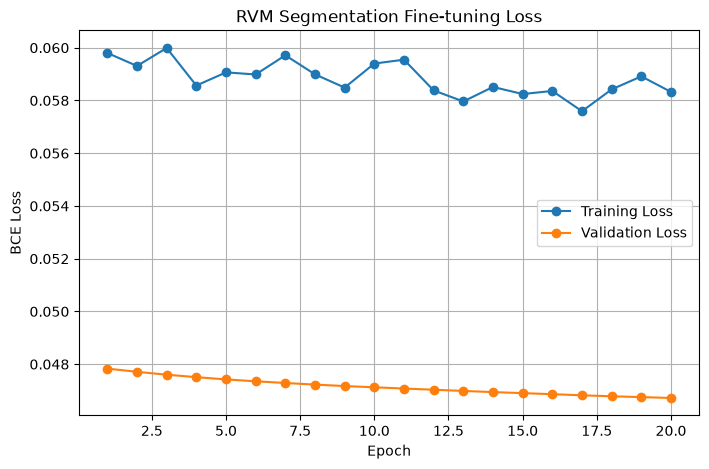

In [71]:
epochs_range = range(
    1,
    len(history["train_loss"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("BCE Loss")

plt.title(
    "RVM Segmentation Fine-tuning Loss"
)

plt.legend()
plt.grid(True)

plt.savefig(
    FIGURE_DIR / "loss_curve.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

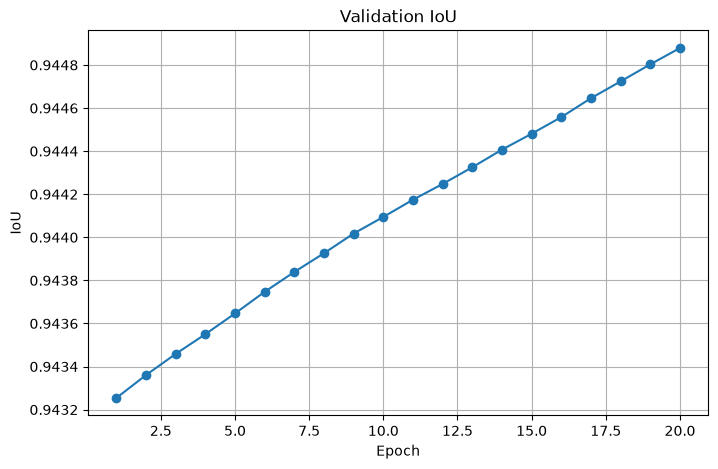

In [72]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    history["val_iou"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("IoU")

plt.title(
    "Validation IoU"
)

plt.grid(True)

plt.savefig(
    FIGURE_DIR / "val_iou.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

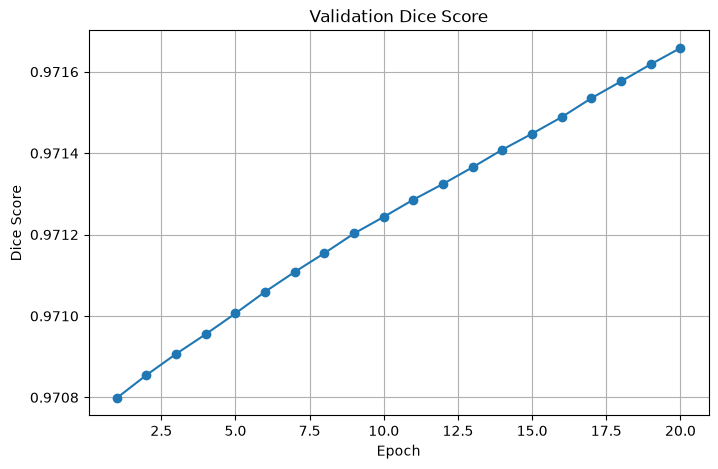

In [73]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    history["val_dice"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Dice Score")

plt.title(
    "Validation Dice Score"
)

plt.grid(True)

plt.savefig(
    FIGURE_DIR / "val_dice.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [74]:
best_epoch_index = int(
    np.argmin(
        history["val_loss"]
    )
)

best_epoch = (
    best_epoch_index + 1
)

print(
    "Best Epoch:",
    best_epoch
)

print(
    "Best Validation Loss:",
    history["val_loss"][
        best_epoch_index
    ]
)

print(
    "Best Validation IoU:",
    history["val_iou"][
        best_epoch_index
    ]
)

print(
    "Best Validation Dice:",
    history["val_dice"][
        best_epoch_index
    ]
)

Best Epoch: 20
Best Validation Loss: 0.04671805046666834
Best Validation IoU: 0.9448789691582948
Best Validation Dice: 0.9716583747802259


In [75]:
checkpoint = torch.load(
    best_checkpoint,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

print(
    "Loaded checkpoint from epoch:",
    checkpoint["epoch"]
)

print(
    "Validation metrics:",
    checkpoint["val_metrics"]
)

Loaded checkpoint from epoch: 20
Validation metrics: {'loss': 0.04671805046666834, 'iou': 0.9448789691582948, 'dice': 0.9716583747802259, 'precision': 0.9735841760223202, 'recall': 0.9697401771721478}


In [76]:
fine_tuned_test = evaluate_model(
    model,
    test_loader
)

print(
    "=== FINE-TUNED MODEL : TEST ==="
)

for key, value in fine_tuned_test.items():

    print(
        f"{key:10s}: "
        f"{value:.4f}"
    )

=== FINE-TUNED MODEL : TEST ===
loss      : 0.0577
iou       : 0.9354
dice      : 0.9666
precision : 0.9728
recall    : 0.9606


In [77]:
comparison = pd.DataFrame({

    "Metric": [
        "BCE Loss",
        "IoU",
        "Dice",
        "Precision",
        "Recall"
    ],

    "Pretrained": [
        baseline_test["loss"],
        baseline_test["iou"],
        baseline_test["dice"],
        baseline_test["precision"],
        baseline_test["recall"]
    ],

    "Fine-tuned": [
        fine_tuned_test["loss"],
        fine_tuned_test["iou"],
        fine_tuned_test["dice"],
        fine_tuned_test["precision"],
        fine_tuned_test["recall"]
    ]
})

comparison

,Metric,Pretrained,Fine-tuned
0,BCE Loss,0.065852,0.057654
1,IoU,0.928751,0.935401
2,Dice,0.963059,0.966622
3,Precision,0.979876,0.972770
4,Recall,0.946810,0.960551


In [78]:
comparison["Change"] = (
    comparison["Fine-tuned"]
    - comparison["Pretrained"]
)

comparison

,Metric,Pretrained,Fine-tuned,Change
0,BCE Loss,0.065852,0.057654,-0.008198
1,IoU,0.928751,0.935401,0.006650
2,Dice,0.963059,0.966622,0.003563
3,Precision,0.979876,0.972770,-0.007106
4,Recall,0.946810,0.960551,0.013741


In [79]:
comparison.to_csv(
    RESULT_DIR /
    "baseline_vs_finetuned.csv",
    index=False
)

comparison

,Metric,Pretrained,Fine-tuned,Change
0,BCE Loss,0.065852,0.057654,-0.008198
1,IoU,0.928751,0.935401,0.006650
2,Dice,0.963059,0.966622,0.003563
3,Precision,0.979876,0.972770,-0.007106
4,Recall,0.946810,0.960551,0.013741


In [80]:
display_comparison = comparison.copy()

for col in [
    "Pretrained",
    "Fine-tuned",
    "Change"
]:
    display_comparison[col] = (
        display_comparison[col]
        .map(lambda x: f"{x:.4f}")
    )

display_comparison

,Metric,Pretrained,Fine-tuned,Change
0,BCE Loss,0.0659,0.0577,-0.0082
1,IoU,0.9288,0.9354,0.0066
2,Dice,0.9631,0.9666,0.0036
3,Precision,0.9799,0.9728,-0.0071
4,Recall,0.9468,0.9606,0.0137


In [81]:
fine_tuned_seg_state = copy.deepcopy(
    model.project_seg.state_dict()
)

print("Fine-tuned segmentation head saved.")

Fine-tuned segmentation head saved.


In [82]:
test_images, test_masks, test_ids_batch = next(
    iter(test_loader)
)

sample_index = 0

sample_image = test_images[
    sample_index:sample_index + 1
].to(device)

sample_mask = test_masks[
    sample_index:sample_index + 1
].to(device)

sample_id = test_ids_batch[
    sample_index
]

print("Sample ID:", sample_id)
print("Image shape:", sample_image.shape)
print("Mask shape :", sample_mask.shape)

Sample ID: ds6_pexels-photo-769773
Image shape: torch.Size([1, 3, 256, 256])
Mask shape : torch.Size([1, 1, 256, 256])


In [83]:
model.project_seg.load_state_dict(
    baseline_seg_state
)

model.eval()

with torch.no_grad():

    baseline_logits, *_ = model(
        sample_image,
        segmentation_pass=True
    )

baseline_prob = torch.sigmoid(
    baseline_logits
)

baseline_mask = (
    baseline_prob >= 0.5
).float()

print(
    "Baseline prediction:",
    baseline_prob.shape
)

Baseline prediction: torch.Size([1, 1, 256, 256])


In [84]:
model.project_seg.load_state_dict(
    fine_tuned_seg_state
)

model.eval()

with torch.no_grad():

    tuned_logits, *_ = model(
        sample_image,
        segmentation_pass=True
    )

tuned_prob = torch.sigmoid(
    tuned_logits
)

tuned_mask = (
    tuned_prob >= 0.5
).float()

print(
    "Fine-tuned prediction:",
    tuned_prob.shape
)

Fine-tuned prediction: torch.Size([1, 1, 256, 256])


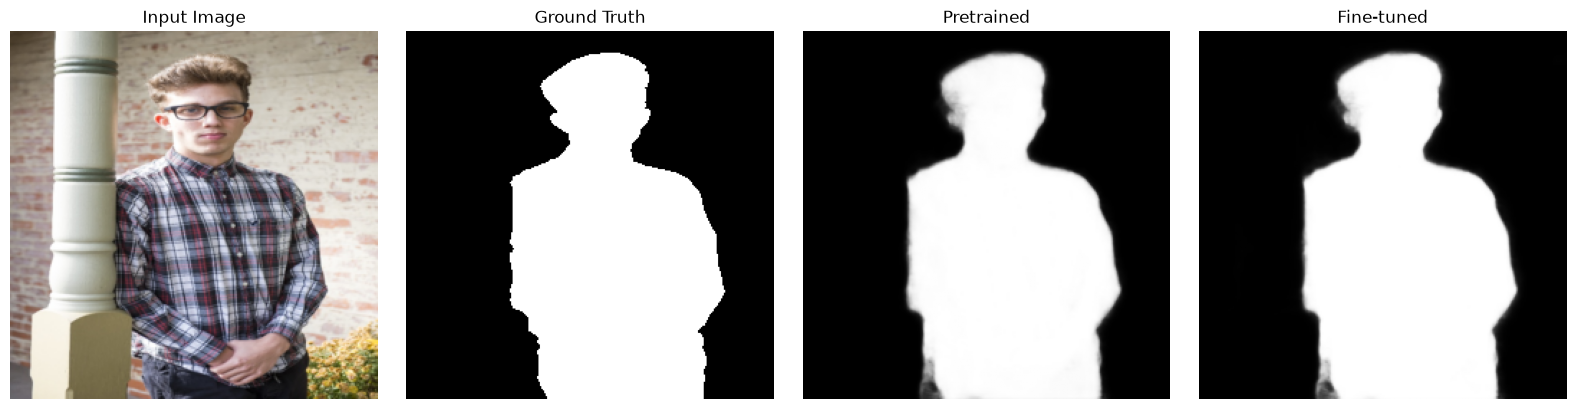

In [85]:
input_np = (
    sample_image[0]
    .detach()
    .cpu()
    .permute(1, 2, 0)
    .numpy()
)

gt_np = (
    sample_mask[0, 0]
    .detach()
    .cpu()
    .numpy()
)

baseline_np = (
    baseline_prob[0, 0]
    .detach()
    .cpu()
    .numpy()
)

tuned_np = (
    tuned_prob[0, 0]
    .detach()
    .cpu()
    .numpy()
)

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(input_np)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(gt_np, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(
    baseline_np,
    cmap="gray",
    vmin=0,
    vmax=1
)
plt.title("Pretrained")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(
    tuned_np,
    cmap="gray",
    vmin=0,
    vmax=1
)
plt.title("Fine-tuned")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "before_after_prediction.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

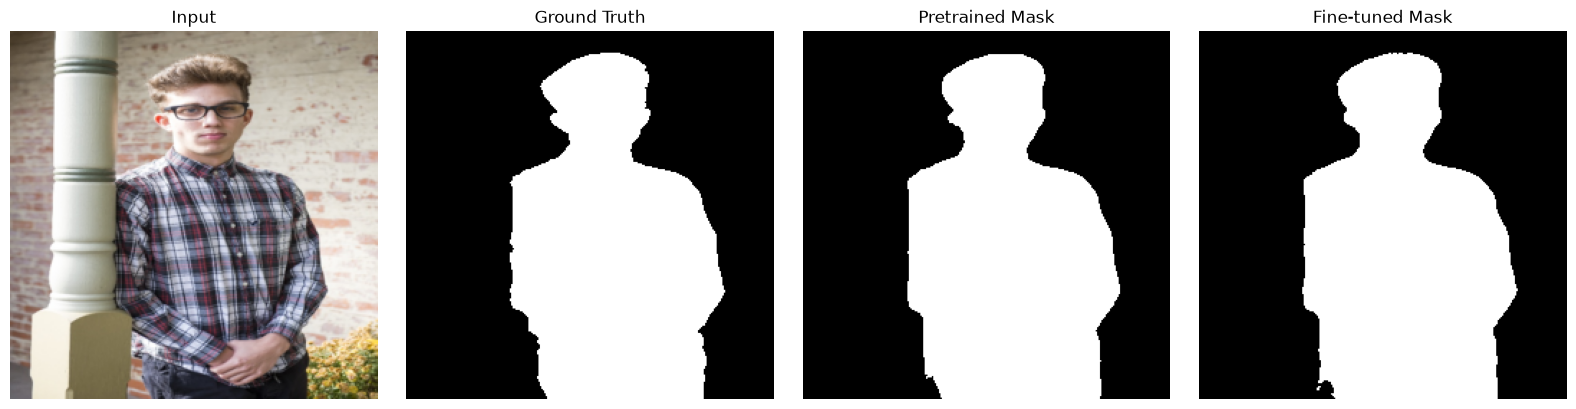

In [86]:
baseline_binary_np = (
    baseline_mask[0, 0]
    .cpu()
    .numpy()
)

tuned_binary_np = (
    tuned_mask[0, 0]
    .cpu()
    .numpy()
)

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(input_np)
plt.title("Input")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(gt_np, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(
    baseline_binary_np,
    cmap="gray"
)
plt.title("Pretrained Mask")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(
    tuned_binary_np,
    cmap="gray"
)
plt.title("Fine-tuned Mask")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "before_after_binary.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [87]:
baseline_sample_metrics = calculate_metrics(
    baseline_logits,
    sample_mask
)

tuned_sample_metrics = calculate_metrics(
    tuned_logits,
    sample_mask
)

print("=== SAMPLE COMPARISON ===")

print("\nPretrained:")
for k, v in baseline_sample_metrics.items():
    print(f"{k:10s}: {v:.4f}")

print("\nFine-tuned:")
for k, v in tuned_sample_metrics.items():
    print(f"{k:10s}: {v:.4f}")

=== SAMPLE COMPARISON ===

Pretrained:
iou       : 0.9797
dice      : 0.9897
precision : 0.9868
recall    : 0.9927

Fine-tuned:
iou       : 0.9777
dice      : 0.9887
precision : 0.9818
recall    : 0.9957


In [88]:
segmentation_pass=True

In [89]:
model.eval()

with torch.no_grad():

    pred_fgr, pred_pha, r1, r2, r3, r4 = model(
        sample_image,
        downsample_ratio=1
    )

print(
    "Foreground:",
    pred_fgr.shape
)

print(
    "Alpha Matte:",
    pred_pha.shape
)

Foreground: torch.Size([1, 3, 256, 256])
Alpha Matte: torch.Size([1, 1, 256, 256])


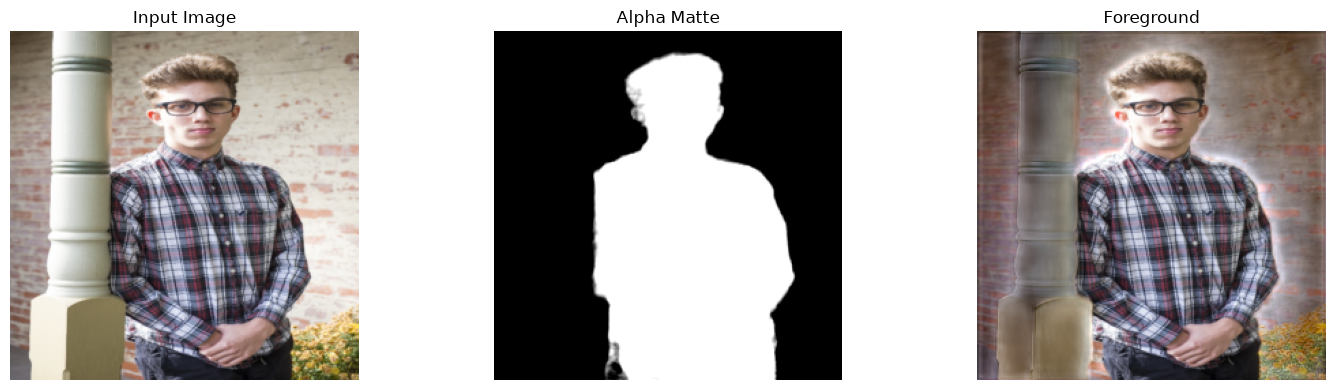

In [90]:
fgr_np = (
    pred_fgr[0]
    .detach()
    .cpu()
    .permute(1, 2, 0)
    .clamp(0, 1)
    .numpy()
)

pha_np = (
    pred_pha[0, 0]
    .detach()
    .cpu()
    .clamp(0, 1)
    .numpy()
)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(input_np)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(
    pha_np,
    cmap="gray",
    vmin=0,
    vmax=1
)
plt.title("Alpha Matte")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(fgr_np)
plt.title("Foreground")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "rvm_matting_result.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

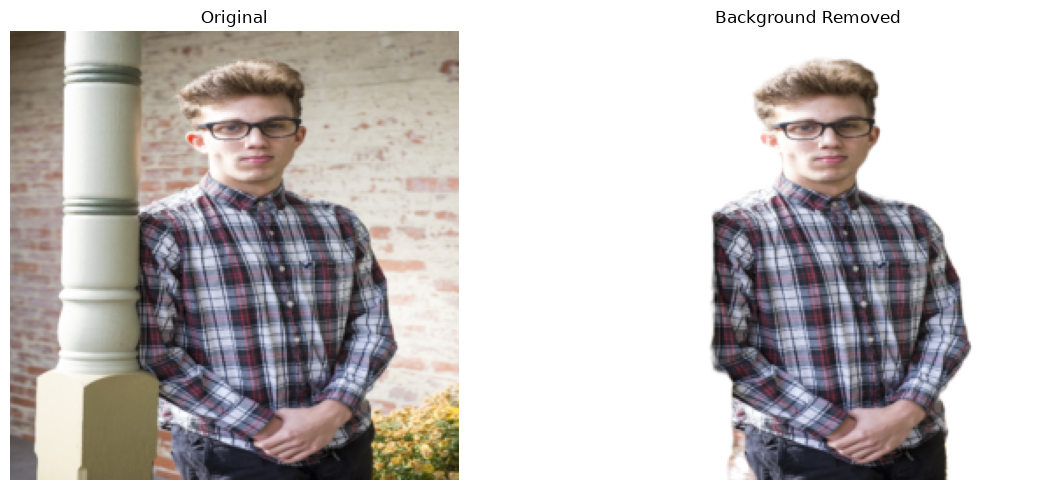

In [91]:
background = torch.ones_like(
    pred_fgr
)

composition = (
    pred_pha * pred_fgr
    +
    (1 - pred_pha) * background
)

composition_np = (
    composition[0]
    .detach()
    .cpu()
    .permute(1, 2, 0)
    .clamp(0, 1)
    .numpy()
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(input_np)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(composition_np)
plt.title("Background Removed")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "background_removed.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [92]:
best_idx = int(
    np.argmin(
        history["val_loss"]
    )
)

summary = {
    "Model":
        "RVM-MobileNetV3",

    "Initialization":
        "Official Pretrained",

    "Dataset":
        "Supervisely Filtered Person Dataset",

    "Total Samples":
        len(sample_ids),

    "Train Samples":
        len(train_ids),

    "Validation Samples":
        len(val_ids),

    "Test Samples":
        len(test_ids),

    "Input Resolution":
        f"{IMAGE_SIZE}x{IMAGE_SIZE}",

    "Batch Size":
        BATCH_SIZE,

    "Epochs":
        EPOCHS,

    "Optimizer":
        "Adam",

    "Learning Rate":
        LEARNING_RATE,

    "Loss":
        "BCEWithLogitsLoss",

    "Fine-tuned Layer":
        "project_seg",

    "Best Epoch":
        best_idx + 1,

    "Training Time (sec)":
        training_seconds,

    "Baseline IoU":
        baseline_test["iou"],

    "Fine-tuned IoU":
        fine_tuned_test["iou"],

    "Baseline Dice":
        baseline_test["dice"],

    "Fine-tuned Dice":
        fine_tuned_test["dice"],

    "Baseline Precision":
        baseline_test["precision"],

    "Fine-tuned Precision":
        fine_tuned_test["precision"],

    "Baseline Recall":
        baseline_test["recall"],

    "Fine-tuned Recall":
        fine_tuned_test["recall"]
}

summary_df = pd.DataFrame(
    [summary]
)

summary_df.T

,0
Model,RVM-MobileNetV3
Initialization,Official Pretrained
Dataset,Supervisely Filtered Person Dataset
Total Samples,2667
Train Samples,2133
Validation Samples,266
Test Samples,268
Input Resolution,256x256
Batch Size,8
Epochs,20


In [93]:
iou_improvement = (
    (
        fine_tuned_test["iou"]
        - baseline_test["iou"]
    )
    /
    baseline_test["iou"]
    * 100
)

dice_improvement = (
    (
        fine_tuned_test["dice"]
        - baseline_test["dice"]
    )
    /
    baseline_test["dice"]
    * 100
)

print(
    f"IoU relative change : "
    f"{iou_improvement:+.2f}%"
)

print(
    f"Dice relative change: "
    f"{dice_improvement:+.2f}%"
)

IoU relative change : +0.72%
Dice relative change: +0.37%


In [94]:
print("=== GENERATED FILES ===")

for path in OUTPUT_DIR.rglob("*"):

    if path.is_file():
        print(
            path.relative_to(
                PROJECT_ROOT
            )
        )

=== GENERATED FILES ===
outputs\checkpoints\rvm_mobilenetv3_supervisely_best.pth
outputs\figures\background_removed.png
outputs\figures\before_after_binary.png
outputs\figures\before_after_prediction.png
outputs\figures\loss_curve.png
outputs\figures\rvm_matting_result.png
outputs\figures\val_dice.png
outputs\figures\val_iou.png
outputs\results\baseline_results.csv
outputs\results\baseline_vs_finetuned.csv
outputs\results\training_history.csv


In [95]:
# Ensure best/final model is loaded
model.eval()

# แนะนำ export บน CPU ก่อน
model_cpu = copy.deepcopy(model).cpu().eval()

scripted_model = torch.jit.script(model_cpu)

EXPORT_PATH = (
    CHECKPOINT_DIR
    / "rvm_mobilenetv3_finetuned.torchscript"
)

scripted_model.save(str(EXPORT_PATH))

print("Saved:", EXPORT_PATH)

Saved: D:\Data\AI-edge\outputs\checkpoints\rvm_mobilenetv3_finetuned.torchscript
